# 23D — External Context Data Integration
## Exact FIRMS points + land cover/change + accessibility + optional lightning/peatland

### Why this notebook exists

NB23C showed that meteorology alone is not sufficient to robustly distinguish
environmentally plausible Emerging-3 events from unusual hotspot events.

This notebook therefore adds **external context**.

The goal is NOT to classify a hotspot as:
- human-caused,
- intentionally burned,
- illegal,
- caused by cigarette ignition,
- plantation clearing,
- or naturally ignited.

Instead, we build an **evidence table** for unusual hotspots.

### Evidence families

1. **Exact FIRMS detections**
   - Move from 0.25° candidate cell-day to the actual VIIRS detection points inside it.

2. **Land cover / land-use context**
   - Dynamic World 10 m probabilities.
   - Pre-event land-cover composition.
   - Same-season year-over-year change signal.

3. **Human-accessibility context**
   - Historical OpenStreetMap road/track geometry if an ohsome API key is available.
   - Distance to the nearest mapped access line.

4. **Lightning evidence — OPTIONAL**
   - If event-level lightning data from BMKG / Vaisala GLD360 / another defensible network
     is placed in the expected input folder, compute recent lightning context.
   - Absence of detected lightning is NOT proof of anthropogenic ignition.

5. **Peatland — OPTIONAL**
   - If a properly sourced peatland polygon dataset is supplied locally,
     mark whether each FIRMS detection falls within mapped peatland.

### Comparison design

We compare two Emerging-3 groups on land-dominant cells:

- **Robust joint-high candidates**
  - history anomaly high
  - environmental anomaly high under both LR and HGB

- **History-novel / environment-plausible controls**
  - history anomaly high
  - environmental anomaly below the high-anomaly threshold under both LR and HGB

This is descriptive contextual analysis, not supervised ignition-cause classification.

## Current external sources used by this notebook

### Dynamic World V1
Google/WRI Dynamic World is a near-real-time 10 m land-cover product based on Sentinel-2,
available from 2015 to present through Google Earth Engine.

Dataset:
`GOOGLE/DYNAMICWORLD/V1`

Nine probability bands:
`water, trees, grass, flooded_vegetation, crops, shrub_and_scrub, built, bare, snow_and_ice`

Official catalog:
https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1

### Historical OpenStreetMap
The **ohsome API** supports historical OSM snapshots.
This notebook requests roads/tracks using a snapshot from **2026-08-01**, before the
August development events.

Documentation:
https://docs.ohsome.org/ohsome-api/v2/

A free API key is required.

### Lightning
No public raw event-level 2026 lightning dataset is assumed.

Preferred options:
- BMKG lightning-detection data if obtainable for research.
- Vaisala GLD360 research archive request.

Vaisala research-request page:
https://www.vaisala.com/en/lp/request-vaisala-lightning-data-research-use

This notebook accepts a local lightning CSV when available.

In [2]:
# 1. Imports

from pathlib import Path
from io import BytesIO
import os
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 300)

GRID_STEP = 0.25
HALF_STEP = GRID_STEP / 2
LAND_THRESHOLD = 0.95
ANOMALY_THRESHOLD = 0.80
POINT_BUFFER_M = 200

In [3]:
# 2. Resolve project root and required NB23C exports

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "model_results"
        / "environmental_context_refinement"
        / "t2"
        / "exports"
        / "august_positive_refined_anomaly.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate NB23C exports. Run NB23C first and make sure "
        "model_results/environmental_context_refinement/t2/exports exists."
    )

NB23C_EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_context_refinement"
    / "t2"
    / "exports"
)

POSITIVE_PATH = (
    NB23C_EXPORT_DIR
    / "august_positive_refined_anomaly.csv"
)

ROBUST_PATH = (
    NB23C_EXPORT_DIR
    / "robust_joint_high_candidates.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "external_context_integration"
    / "t2"
)

EXPORT_DIR = OUTPUT_DIR / "exports"
FIGURES_DIR = OUTPUT_DIR / "figures"
CACHE_DIR = OUTPUT_DIR / "cache"

for p in [OUTPUT_DIR, EXPORT_DIR, FIGURES_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("NB23C exports:", NB23C_EXPORT_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
NB23C exports: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_context_refinement\t2\exports
OUTPUT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2


In [4]:
# 3. Load NB23C positive events

pos = pd.read_csv(
    POSITIVE_PATH,
    parse_dates=["date", "event_date"],
)

robust = pd.read_csv(
    ROBUST_PATH,
    parse_dates=["date", "event_date"],
)

LR_RANK = "env_rank__E2_ANTECEDENT_LAND_LR"
HGB_RANK = "env_rank__E3_ANTECEDENT_LAND_HGB"
HISTORY_RANK = "history_anomaly_day_rank"

required = {
    "date",
    "event_date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "research_group",
    "land_fraction",
    HISTORY_RANK,
    LR_RANK,
    HGB_RANK,
}

missing = sorted(required - set(pos.columns))
if missing:
    raise ValueError(
        "Missing required NB23C columns:\n"
        + "\n".join(f"- {x}" for x in missing)
    )

print("NB23C positive events:", len(pos))
print("NB23C robust candidates:", len(robust))

NB23C positive events: 2066
NB23C robust candidates: 20


# PART A — Define comparison groups

We use land-dominant cells (`land_fraction >= 0.95`) to reduce the mixed-water issue found in NB23B/NB23C.

### Candidate group
Emerging-3 + high history anomaly + high environmental anomaly under BOTH refined models.

### Comparator group
Emerging-3 + high history anomaly, but environmental anomaly is below 0.80 under BOTH refined models.

The comparator is useful because both groups are "new" relative to recent fire history.
The main contrast is whether environmental conditions also appear unusual.

In [5]:
# 4. Candidate and comparator groups

base = pos[
    pos["research_group"].eq("Emerging-3")
    & pos["land_fraction"].ge(LAND_THRESHOLD)
    & pos[HISTORY_RANK].ge(ANOMALY_THRESHOLD)
].copy()

candidate_mask = (
    base[LR_RANK].ge(ANOMALY_THRESHOLD)
    & base[HGB_RANK].ge(ANOMALY_THRESHOLD)
)

control_mask = (
    base[LR_RANK].lt(ANOMALY_THRESHOLD)
    & base[HGB_RANK].lt(ANOMALY_THRESHOLD)
)

candidates = base.loc[candidate_mask].copy()
controls = base.loc[control_mask].copy()

candidates["context_group"] = "Robust joint-high"
controls["context_group"] = "History-novel / env-plausible"

analysis_cells = pd.concat(
    [candidates, controls],
    ignore_index=True,
).copy()

analysis_cells["candidate_event_id"] = (
    analysis_cells["event_date"].dt.strftime("%Y-%m-%d")
    + "__"
    + analysis_cells["cell_id"].astype(str)
)

print("Land threshold:", LAND_THRESHOLD)
print("Robust joint-high candidates:", len(candidates))
print("History-novel / env-plausible controls:", len(controls))

display(
    analysis_cells[
        [
            "candidate_event_id",
            "context_group",
            "event_date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "land_fraction",
            HISTORY_RANK,
            LR_RANK,
            HGB_RANK,
        ]
    ].sort_values(["context_group", "event_date"])
)

Land threshold: 0.95
Robust joint-high candidates: 6
History-novel / env-plausible controls: 53


,candidate_event_id,context_group,event_date,cell_id,grid_lat,grid_lon,land_fraction,history_anomaly_day_rank,env_rank__E2_ANTECEDENT_LAND_LR,env_rank__E3_ANTECEDENT_LAND_HGB
8,2026-08-06__regional025_10_24,History-novel / env-plausible,2026-08-06,regional025_10_24,-1.875,114.125,1.000000,0.819549,0.436090,0.127820
24,2026-08-06__regional025_13_28,History-novel / env-plausible,2026-08-06,regional025_13_28,-1.125,115.125,1.000000,0.819549,0.699248,0.496241
34,2026-08-06__regional025_3_30,History-novel / env-plausible,2026-08-06,regional025_3_30,-3.625,115.625,0.959919,0.819549,0.736842,0.639098
36,2026-08-06__regional025_4_30,History-novel / env-plausible,2026-08-06,regional025_4_30,-3.375,115.625,1.000000,0.819549,0.390977,0.421053
40,2026-08-06__regional025_6_22,History-novel / env-plausible,2026-08-06,regional025_6_22,-2.875,113.625,1.000000,0.819549,0.278195,0.165414
42,2026-08-06__regional025_6_23,History-novel / env-plausible,2026-08-06,regional025_6_23,-2.875,113.875,1.000000,0.819549,0.300752,0.150376
45,2026-08-06__regional025_6_27,History-novel / env-plausible,2026-08-06,regional025_6_27,-2.875,114.875,1.000000,0.819549,0.097744,0.533835
54,2026-08-06__regional025_9_24,History-novel / env-plausible,2026-08-06,regional025_9_24,-2.125,114.125,1.000000,0.819549,0.368421,0.518797
7,2026-08-07__regional025_10_23,History-novel / env-plausible,2026-08-07,regional025_10_23,-1.875,113.875,1.000000,0.857143,0.654135,0.285714
57,2026-08-07__regional025_9_28,History-novel / env-plausible,2026-08-07,regional025_9_28,-2.125,115.125,1.000000,0.857143,0.353383,0.676692


# PART B — Expand candidate cell-days to exact FIRMS detections

The model operates on 0.25° cells, but FIRMS itself contains point detections.

For every candidate/comparator cell-day, this notebook loads the raw FIRMS file for the
**event date** (`t+1`) and retains points inside:

- longitude: grid center ± 0.125°
- latitude: grid center ± 0.125°

Important:
- Multiple FIRMS rows can represent repeated detections / different pixels of one fire.
- Therefore, exact FIRMS rows are used for spatial context, then aggregated back to the
  candidate **cell-day** for inference.

In [6]:
# 5. Locate raw FIRMS files

RAW_FIRE_DIR_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "KARHUT_Data_Share" / "data" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "data" / "raw" / "kalimantan" / "fire_firms" / "daily",
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "daily",
]

RAW_FIRE_DIR = None

for candidate in RAW_FIRE_DIR_CANDIDATES:
    if candidate.exists() and list(candidate.glob("fires_*.csv")):
        RAW_FIRE_DIR = candidate
        break

if RAW_FIRE_DIR is None:
    matches = []

    for p in PROJECT_ROOT.rglob("fires_*.csv"):
        s = str(p).lower()
        if "fire_firms" in s and "kalimantan" in s:
            matches.append(p.parent)

    if matches:
        # Prefer a path containing hourly.
        matches = sorted(
            set(matches),
            key=lambda x: (
                "hourly" not in str(x).lower(),
                len(str(x)),
            ),
        )
        RAW_FIRE_DIR = matches[0]

if RAW_FIRE_DIR is None:
    raise FileNotFoundError(
        "Could not locate raw Kalimantan FIRMS fires_YYYY-MM-DD.csv files."
    )

print("RAW_FIRE_DIR:", RAW_FIRE_DIR)

RAW_FIRE_DIR: c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\fire_firms\hourly


In [7]:
# 6. FIRMS utility functions

def detect_lat_lon_columns(df):
    candidates = [
        ("lat", "lon"),
        ("latitude", "longitude"),
        ("Latitude", "Longitude"),
        ("LATITUDE", "LONGITUDE"),
    ]

    for lat_col, lon_col in candidates:
        if lat_col in df.columns and lon_col in df.columns:
            return lat_col, lon_col

    lower_map = {c.lower(): c for c in df.columns}

    if "latitude" in lower_map and "longitude" in lower_map:
        return lower_map["latitude"], lower_map["longitude"]

    if "lat" in lower_map and "lon" in lower_map:
        return lower_map["lat"], lower_map["lon"]

    raise ValueError("Could not detect latitude/longitude columns.")


def normalize_firms_time(df, event_date):
    result = df.copy()
    result["firms_time_utc"] = pd.NaT
    result["firms_time_quality"] = "date_only"

    lower = {c.lower(): c for c in result.columns}

    # Best case: explicit datetime/timestamp column.
    for key in ["time_utc", "datetime", "timestamp", "acq_datetime"]:
        if key in lower:
            parsed = pd.to_datetime(
                result[lower[key]],
                errors="coerce",
                utc=True,
            )
            if parsed.notna().any():
                result["firms_time_utc"] = parsed
                result["firms_time_quality"] = "timestamp"
                return result

    # Common FIRMS schema: acq_date + acq_time (HHMM).
    if "acq_date" in lower and "acq_time" in lower:
        dates = pd.to_datetime(
            result[lower["acq_date"]],
            errors="coerce",
        )

        times = (
            result[lower["acq_time"]]
            .astype(str)
            .str.replace(r"\.0$", "", regex=True)
            .str.zfill(4)
        )

        combined = pd.to_datetime(
            dates.dt.strftime("%Y-%m-%d")
            + " "
            + times.str[:2]
            + ":"
            + times.str[2:],
            errors="coerce",
            utc=True,
        )

        if combined.notna().any():
            result["firms_time_utc"] = combined
            result["firms_time_quality"] = "timestamp"
            return result

    # Honest fallback: preserve event date only; do not invent an hour.
    result["firms_event_date"] = pd.Timestamp(event_date).normalize()
    return result


def load_firms_date(event_date):
    event_date = pd.Timestamp(event_date)
    path = RAW_FIRE_DIR / f"fires_{event_date.date()}.csv"

    if not path.exists():
        return pd.DataFrame()

    df = pd.read_csv(path)

    if df.empty:
        return df

    lat_col, lon_col = detect_lat_lon_columns(df)

    df = df.rename(
        columns={
            lat_col: "firms_lat",
            lon_col: "firms_lon",
        }
    )

    df["firms_lat"] = pd.to_numeric(
        df["firms_lat"],
        errors="coerce",
    )
    df["firms_lon"] = pd.to_numeric(
        df["firms_lon"],
        errors="coerce",
    )

    if "frp" in df.columns:
        df["firms_frp"] = pd.to_numeric(
            df["frp"],
            errors="coerce",
        )
    else:
        df["firms_frp"] = np.nan

    df = df.dropna(
        subset=["firms_lat", "firms_lon"]
    ).copy()

    df = normalize_firms_time(
        df,
        event_date,
    )

    df["source_file"] = str(path)

    return df.reset_index(drop=True)

In [8]:
# 7. Match exact FIRMS points to candidate cell-days

point_rows = []

for row in analysis_cells.itertuples(index=False):
    firms = load_firms_date(row.event_date)

    if firms.empty:
        print(
            "WARNING: no raw FIRMS points for",
            row.candidate_event_id,
        )
        continue

    west = row.grid_lon - HALF_STEP
    east = row.grid_lon + HALF_STEP
    south = row.grid_lat - HALF_STEP
    north = row.grid_lat + HALF_STEP

    inside = firms[
        firms["firms_lon"].between(
            west,
            east,
            inclusive="both",
        )
        &
        firms["firms_lat"].between(
            south,
            north,
            inclusive="both",
        )
    ].copy()

    if inside.empty:
        print(
            "WARNING: model cell is positive but no exact FIRMS point "
            "was recovered:",
            row.candidate_event_id,
        )
        continue

    inside["candidate_event_id"] = row.candidate_event_id
    inside["context_group"] = row.context_group
    inside["event_date"] = row.event_date
    inside["cell_id"] = row.cell_id
    inside["grid_lat"] = row.grid_lat
    inside["grid_lon"] = row.grid_lon
    inside["land_fraction"] = row.land_fraction
    inside["history_anomaly_rank"] = getattr(
        row,
        HISTORY_RANK,
    )
    inside["env_anomaly_lr"] = getattr(
        row,
        LR_RANK,
    )
    inside["env_anomaly_hgb"] = getattr(
        row,
        HGB_RANK,
    )

    point_rows.append(inside)

if not point_rows:
    raise RuntimeError(
        "No exact FIRMS points were matched to the selected cell-days."
    )

firms_points = pd.concat(
    point_rows,
    ignore_index=True,
)

firms_points["firms_point_id"] = [
    f"fp_{i:06d}"
    for i in range(len(firms_points))
]

print("Exact FIRMS detections:", len(firms_points))
print("Candidate cell-days represented:", firms_points["candidate_event_id"].nunique())

display(
    firms_points[
        [
            "firms_point_id",
            "candidate_event_id",
            "context_group",
            "event_date",
            "firms_lat",
            "firms_lon",
            "firms_frp",
            "firms_time_quality",
        ]
    ].head(30)
)

Exact FIRMS detections: 126
Candidate cell-days represented: 59


,firms_point_id,candidate_event_id,context_group,event_date,firms_lat,firms_lon,firms_frp,firms_time_quality
0,fp_000000,2026-08-17__regional025_12_33,Robust joint-high,2026-08-17,-1.41518,116.42889,1.65,timestamp
1,fp_000001,2026-08-17__regional025_12_33,Robust joint-high,2026-08-17,-1.49871,116.29330,5.12,timestamp
2,fp_000002,2026-08-17__regional025_12_33,Robust joint-high,2026-08-17,-1.41124,116.43201,3.48,timestamp
3,fp_000003,2026-08-26__regional025_12_33,Robust joint-high,2026-08-26,-1.49381,116.44941,9.02,timestamp
4,fp_000004,2026-08-26__regional025_12_33,Robust joint-high,2026-08-26,-1.49569,116.45148,5.11,timestamp
5,fp_000005,2026-08-26__regional025_12_33,Robust joint-high,2026-08-26,-1.49637,116.44709,5.11,timestamp
6,fp_000006,2026-08-26__regional025_12_33,Robust joint-high,2026-08-26,-1.49326,116.29182,6.85,timestamp
7,fp_000007,2026-08-26__regional025_13_33,Robust joint-high,2026-08-26,-1.12715,116.44953,5.58,timestamp
8,fp_000008,2026-08-26__regional025_13_33,Robust joint-high,2026-08-26,-1.13159,116.45048,5.58,timestamp
9,fp_000009,2026-08-17__regional025_7_32,Robust joint-high,2026-08-17,-2.51700,116.12626,3.49,timestamp


In [9]:
# 8. Raw FIRMS point-count audit by candidate cell-day

firms_cell_audit = (
    firms_points
    .groupby(
        [
            "candidate_event_id",
            "context_group",
            "event_date",
            "cell_id",
        ]
    )
    .agg(
        exact_firms_detections=("firms_point_id", "size"),
        firms_frp_sum=("firms_frp", "sum"),
        firms_frp_max=("firms_frp", "max"),
    )
    .reset_index()
)

display(
    firms_cell_audit.sort_values(
        ["context_group", "exact_firms_detections"],
        ascending=[True, False],
    )
)

,candidate_event_id,context_group,event_date,cell_id,exact_firms_detections,firms_frp_sum,firms_frp_max
11,2026-08-08__regional025_8_25,History-novel / env-plausible,2026-08-08,regional025_8_25,8,32.81,9.83
23,2026-08-15__regional025_2_27,History-novel / env-plausible,2026-08-15,regional025_2_27,6,20.75,6.70
8,2026-08-07__regional025_10_23,History-novel / env-plausible,2026-08-07,regional025_10_23,5,13.10,4.35
26,2026-08-16__regional025_6_25,History-novel / env-plausible,2026-08-16,regional025_6_25,5,41.76,14.46
27,2026-08-17__regional025_10_22,History-novel / env-plausible,2026-08-17,regional025_10_22,5,19.81,6.23
7,2026-08-06__regional025_9_24,History-novel / env-plausible,2026-08-06,regional025_9_24,4,3.34,0.85
16,2026-08-10__regional025_9_26,History-novel / env-plausible,2026-08-10,regional025_9_26,4,12.70,3.79
31,2026-08-17__regional025_5_25,History-novel / env-plausible,2026-08-17,regional025_5_25,4,16.20,5.10
49,2026-08-26__regional025_6_22,History-novel / env-plausible,2026-08-26,regional025_6_22,4,21.72,6.44
12,2026-08-08__regional025_9_22,History-novel / env-plausible,2026-08-08,regional025_9_22,3,11.99,10.05


# PART C — Dynamic World land-cover context

This section is OPTIONAL at runtime because Earth Engine authentication is required.

### Pre-event composite
For each FIRMS point:
- recent window = 60 days before event, excluding event day.

### Same-season prior-year reference
- reference window = the same relative 60-day window one year earlier.

This gives:
- recent pre-event land-cover probabilities;
- year-over-year probability deltas.

Examples:
- `dw_delta_trees < 0` may indicate reduced tree-cover probability.
- `dw_delta_bare > 0` may indicate increased bare-ground probability.
- `dw_delta_crops > 0` may indicate increased crop probability.

These are **change signals**, NOT confirmed deforestation or plantation clearing.
Clouds, seasonality, crop cycles, and model uncertainty remain relevant.

In [10]:
# 9. Earth Engine configuration

EE_PROJECT = os.getenv("EE_PROJECT", "").strip()

print("EE_PROJECT:", EE_PROJECT if EE_PROJECT else "<not set>")

print(
    "\nTo use Dynamic World locally:\n"
    "1) pip install earthengine-api\n"
    "2) create/use a Google Earth Engine Cloud project\n"
    "3) set environment variable EE_PROJECT to that project ID\n"
    "4) run ee.Authenticate() once if needed\n"
)

EE_PROJECT: <not set>

To use Dynamic World locally:
1) pip install earthengine-api
2) create/use a Google Earth Engine Cloud project
3) set environment variable EE_PROJECT to that project ID
4) run ee.Authenticate() once if needed



In [11]:
# 10. Initialize Earth Engine if available

EE_AVAILABLE = False
ee = None

try:
    import ee as _ee
    ee = _ee

    try:
        if EE_PROJECT:
            ee.Initialize(project=EE_PROJECT)
        else:
            ee.Initialize()

        EE_AVAILABLE = True
        print("Earth Engine initialized.")
    except Exception as exc:
        print("Earth Engine is installed but not initialized.")
        print("Run the following manually, then rerun this cell:")
        print("    ee.Authenticate()")
        print("    ee.Initialize(project='YOUR_PROJECT_ID')")
        print("Reason:", repr(exc))

except ImportError:
    print(
        "earthengine-api is not installed. "
        "Dynamic World section will be skipped."
    )

print("EE_AVAILABLE:", EE_AVAILABLE)

earthengine-api is not installed. Dynamic World section will be skipped.
EE_AVAILABLE: False


In [12]:
# 11. Dynamic World extraction functions

DW_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice",
]


def dw_window_mean(start_date, end_date):
    collection = (
        ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
        .filterDate(
            str(pd.Timestamp(start_date).date()),
            str(pd.Timestamp(end_date).date()),
        )
    )

    return (
        collection
        .select(DW_BANDS)
        .mean()
    )


def extract_dynamic_world_for_date(points_df, event_date):
    event_date = pd.Timestamp(event_date)

    recent_start = event_date - pd.Timedelta(days=60)
    recent_end = event_date

    ref_start = recent_start - pd.DateOffset(years=1)
    ref_end = recent_end - pd.DateOffset(years=1)

    recent = dw_window_mean(
        recent_start,
        recent_end,
    ).rename(
        [f"dw_recent_{b}" for b in DW_BANDS]
    )

    reference = dw_window_mean(
        ref_start,
        ref_end,
    ).rename(
        [f"dw_ref_{b}" for b in DW_BANDS]
    )

    delta = (
        recent.select(
            [f"dw_recent_{b}" for b in DW_BANDS]
        )
        .subtract(
            reference.select(
                [f"dw_ref_{b}" for b in DW_BANDS]
            )
        )
        .rename(
            [f"dw_delta_{b}" for b in DW_BANDS]
        )
    )

    image = (
        recent
        .addBands(reference)
        .addBands(delta)
    )

    features = []

    for row in points_df.itertuples(index=False):
        geometry = (
            ee.Geometry.Point(
                [
                    float(row.firms_lon),
                    float(row.firms_lat),
                ]
            )
            .buffer(POINT_BUFFER_M)
        )

        features.append(
            ee.Feature(
                geometry,
                {
                    "firms_point_id": row.firms_point_id,
                    "candidate_event_id": row.candidate_event_id,
                },
            )
        )

    fc = ee.FeatureCollection(features)

    reduced = image.reduceRegions(
        collection=fc,
        reducer=ee.Reducer.mean(),
        scale=10,
        tileScale=4,
    )

    info = reduced.getInfo()

    rows = []

    for feature in info.get("features", []):
        props = feature.get("properties", {})
        rows.append(props)

    return pd.DataFrame(rows)

In [13]:
# 12. Run Dynamic World extraction

DW_CACHE_PATH = CACHE_DIR / "dynamic_world_point_context.csv"

if DW_CACHE_PATH.exists():
    dw_context = pd.read_csv(DW_CACHE_PATH)
    print("Loaded cached Dynamic World context:", DW_CACHE_PATH)

elif EE_AVAILABLE:
    dw_parts = []

    for event_date, subset in firms_points.groupby("event_date"):
        print(
            "Dynamic World:",
            pd.Timestamp(event_date).date(),
            "| points:",
            len(subset),
        )

        part = extract_dynamic_world_for_date(
            subset,
            event_date,
        )

        if len(part):
            dw_parts.append(part)

    dw_context = (
        pd.concat(
            dw_parts,
            ignore_index=True,
        )
        if dw_parts
        else pd.DataFrame()
    )

    if len(dw_context):
        dw_context.to_csv(
            DW_CACHE_PATH,
            index=False,
        )
        print("Cached:", DW_CACHE_PATH)

else:
    dw_context = pd.DataFrame()
    print("Dynamic World skipped.")

print("Dynamic World rows:", len(dw_context))

Dynamic World skipped.
Dynamic World rows: 0


In [14]:
# 13. Merge Dynamic World point context

points_context = firms_points.copy()

if len(dw_context):
    points_context = points_context.merge(
        dw_context,
        on=[
            "firms_point_id",
            "candidate_event_id",
        ],
        how="left",
        validate="one_to_one",
    )

    print(
        "Dynamic World non-null coverage:",
        round(
            points_context["dw_recent_trees"]
            .notna()
            .mean(),
            4,
        ),
    )
else:
    for prefix in ["dw_recent", "dw_ref", "dw_delta"]:
        for band in DW_BANDS:
            points_context[f"{prefix}_{band}"] = np.nan

# PART D — Historical road / track accessibility

Recommended source: **ohsome API**, because it can return a historical OSM snapshot.

This notebook uses:
- snapshot date: `2026-08-01`
- filter: all OSM `highway=*` line features

This captures mapped roads, tracks, paths, and similar access lines before the August events.

Important:
- OSM completeness varies spatially.
- A missing mapped road does not prove no access exists.
- Proximity to a road/track does not prove human ignition.

A free ohsome API key is required:
https://docs.ohsome.org/ohsome-api/v2/

In [15]:
# 14. Ohsome API configuration

OHSOME_API_KEY = os.getenv(
    "OHSOME_API_KEY",
    "",
).strip()

OHSOME_API_URL = os.getenv(
    "OHSOME_API_URL",
    "https://api.heigit.org/ohsome-api/v2",
).rstrip("/")

OSM_SNAPSHOT_TIME = "2026-08-01T00:00:00Z"

print(
    "OHSOME_API_KEY:",
    "<set>" if OHSOME_API_KEY else "<not set>",
)
print("OHSOME_API_URL:", OHSOME_API_URL)
print("OSM snapshot:", OSM_SNAPSHOT_TIME)

OHSOME_API_KEY: <not set>
OHSOME_API_URL: https://api.heigit.org/ohsome-api/v2
OSM snapshot: 2026-08-01T00:00:00Z


In [16]:
# 15. Extract historical OSM access lines if possible

OSM_CACHE_PATH = CACHE_DIR / "osm_access_2026-08-01.parquet"

osm_access = None

try:
    import geopandas as gpd
except ImportError:
    gpd = None
    print("geopandas not installed; OSM section will be skipped.")

if gpd is not None and OSM_CACHE_PATH.exists():
    osm_access = gpd.read_parquet(OSM_CACHE_PATH)
    print("Loaded cached OSM access:", len(osm_access))

elif gpd is not None and OHSOME_API_KEY:
    try:
        import httpx

        west = float(analysis_cells["grid_lon"].min() - HALF_STEP)
        east = float(analysis_cells["grid_lon"].max() + HALF_STEP)
        south = float(analysis_cells["grid_lat"].min() - HALF_STEP)
        north = float(analysis_cells["grid_lat"].max() + HALF_STEP)

        response = httpx.post(
            OHSOME_API_URL + "/extraction/features.parquet",
            json={
                "aoi": [west, south, east, north],
                "filter": "highway=* and geometry:line",
                "time": OSM_SNAPSHOT_TIME,
                "clip": True,
            },
            headers={
                "authorization": OHSOME_API_KEY,
            },
            timeout=240.0,
        )

        response.raise_for_status()

        osm_access = gpd.read_parquet(
            BytesIO(response.content),
        )

        osm_access.to_parquet(
            OSM_CACHE_PATH,
            index=False,
        )

        print(
            "Downloaded historical OSM access lines:",
            len(osm_access),
        )
        print("Cached:", OSM_CACHE_PATH)

    except Exception as exc:
        osm_access = None
        print("Ohsome extraction failed:", repr(exc))

else:
    print(
        "Historical OSM extraction skipped. "
        "Set OHSOME_API_KEY to enable it."
    )

Historical OSM extraction skipped. Set OHSOME_API_KEY to enable it.


In [17]:
# 16. Nearest mapped-access distance

points_context["road_distance_km"] = np.nan

if gpd is not None and osm_access is not None and len(osm_access):
    from pyproj import CRS

    points_gdf = gpd.GeoDataFrame(
        points_context[
            [
                "firms_point_id",
                "firms_lon",
                "firms_lat",
            ]
        ].copy(),
        geometry=gpd.points_from_xy(
            points_context["firms_lon"],
            points_context["firms_lat"],
        ),
        crs="EPSG:4326",
    )

    center_lon = float(
        analysis_cells["grid_lon"].mean()
    )
    center_lat = float(
        analysis_cells["grid_lat"].mean()
    )

    local_crs = CRS.from_proj4(
        f"+proj=aeqd +lat_0={center_lat} +lon_0={center_lon} "
        "+datum=WGS84 +units=m +no_defs"
    )

    p_local = points_gdf.to_crs(local_crs)
    r_local = osm_access.to_crs(local_crs)

    road_union = r_local.geometry.union_all()

    distances_m = p_local.geometry.distance(
        road_union
    )

    distance_table = pd.DataFrame({
        "firms_point_id": p_local["firms_point_id"],
        "road_distance_km": distances_m / 1000.0,
    })

    points_context = (
        points_context
        .drop(columns=["road_distance_km"])
        .merge(
            distance_table,
            on="firms_point_id",
            how="left",
            validate="one_to_one",
        )
    )

    print(
        "Mapped-access distance coverage:",
        round(
            points_context["road_distance_km"]
            .notna()
            .mean(),
            4,
        ),
    )
else:
    print("Mapped-access distance unavailable.")

Mapped-access distance unavailable.


# PART E — Optional lightning evidence

Expected local file:

`data/external/lightning/lightning_events.csv`

Minimum required information:
- event timestamp in UTC
- latitude
- longitude

Accepted example columns:
- time: `time_utc`, `timestamp`, `datetime`
- latitude: `lat`, `latitude`
- longitude: `lon`, `longitude`

For each exact FIRMS detection, when an exact FIRMS timestamp exists, this notebook computes:

- lightning count within 20 km during prior 24 h
- lightning count within 20 km during prior 48 h
- lightning count within 20 km during prior 72 h
- nearest lightning distance during prior 72 h
- hours since nearest lightning during prior 72 h

If exact FIRMS acquisition time is unavailable, lightning matching is left missing.
We do NOT invent an ignition time.

No lightning detection ≠ proof of anthropogenic ignition.

In [18]:
# 17. Lightning input utilities

LIGHTNING_PATH = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "lightning"
    / "lightning_events.csv"
)


def detect_column(df, candidates):
    lower = {
        c.lower(): c
        for c in df.columns
    }

    for c in candidates:
        if c.lower() in lower:
            return lower[c.lower()]

    return None


def load_lightning(path):
    df = pd.read_csv(path)

    time_col = detect_column(
        df,
        [
            "time_utc",
            "timestamp",
            "datetime",
            "time",
        ],
    )

    lat_col = detect_column(
        df,
        ["lat", "latitude"],
    )

    lon_col = detect_column(
        df,
        ["lon", "longitude"],
    )

    if not all([time_col, lat_col, lon_col]):
        raise ValueError(
            "Lightning CSV must contain timestamp, latitude, and longitude."
        )

    out = pd.DataFrame({
        "lightning_time_utc": pd.to_datetime(
            df[time_col],
            errors="coerce",
            utc=True,
        ),
        "lightning_lat": pd.to_numeric(
            df[lat_col],
            errors="coerce",
        ),
        "lightning_lon": pd.to_numeric(
            df[lon_col],
            errors="coerce",
        ),
    })

    return (
        out.dropna()
        .sort_values("lightning_time_utc")
        .reset_index(drop=True)
    )


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return (
        2
        * 6371.0088
        * np.arcsin(np.sqrt(a))
    )

In [19]:
# 18. Compute lightning context when available

LIGHTNING_AVAILABLE = LIGHTNING_PATH.exists()

for c in [
    "lightning_count_24h_20km",
    "lightning_count_48h_20km",
    "lightning_count_72h_20km",
    "nearest_lightning_72h_km",
    "hours_since_nearest_lightning_72h",
]:
    points_context[c] = np.nan

if LIGHTNING_AVAILABLE:
    lightning = load_lightning(
        LIGHTNING_PATH
    )

    print(
        "Lightning rows:",
        len(lightning),
        "|",
        lightning["lightning_time_utc"].min(),
        "→",
        lightning["lightning_time_utc"].max(),
    )

    for idx, row in points_context.iterrows():
        event_time = row.get(
            "firms_time_utc",
            pd.NaT,
        )

        if pd.isna(event_time):
            continue

        event_time = pd.Timestamp(event_time)

        if event_time.tzinfo is None:
            event_time = event_time.tz_localize("UTC")

        recent72 = lightning[
            lightning["lightning_time_utc"].between(
                event_time - pd.Timedelta(hours=72),
                event_time,
                inclusive="left",
            )
        ].copy()

        if recent72.empty:
            points_context.loc[
                idx,
                [
                    "lightning_count_24h_20km",
                    "lightning_count_48h_20km",
                    "lightning_count_72h_20km",
                ],
            ] = 0
            continue

        distances = haversine_km(
            float(row["firms_lat"]),
            float(row["firms_lon"]),
            recent72["lightning_lat"].to_numpy(),
            recent72["lightning_lon"].to_numpy(),
        )

        recent72["distance_km"] = distances
        near = recent72[
            recent72["distance_km"] <= 20
        ].copy()

        for hours in [24, 48, 72]:
            window_start = (
                event_time
                - pd.Timedelta(hours=hours)
            )

            count = (
                near["lightning_time_utc"]
                .between(
                    window_start,
                    event_time,
                    inclusive="left",
                )
                .sum()
            )

            points_context.loc[
                idx,
                f"lightning_count_{hours}h_20km",
            ] = int(count)

        if len(near):
            nearest_idx = near[
                "distance_km"
            ].idxmin()

            nearest = near.loc[
                nearest_idx
            ]

            points_context.loc[
                idx,
                "nearest_lightning_72h_km",
            ] = float(
                nearest["distance_km"]
            )

            points_context.loc[
                idx,
                "hours_since_nearest_lightning_72h",
            ] = float(
                (
                    event_time
                    - nearest["lightning_time_utc"]
                ).total_seconds()
                / 3600.0
            )

else:
    print(
        "Lightning file not present. "
        "Lightning features remain NaN."
    )

Lightning file not present. Lightning features remain NaN.


# PART F — Optional peatland polygons

Expected directory:

`data/external/peatland/`

Supported if present:
- `peatland.geojson`
- `peatland.gpkg`
- `peatland.shp`

Only use a peatland layer if its provenance, date, and license are documented.

The notebook records only:
`in_mapped_peatland`

This does not imply ignition cause.

In [20]:
# 19. Optional peatland join

points_context["in_mapped_peatland"] = np.nan

PEAT_DIR = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "peatland"
)

peat_candidates = [
    PEAT_DIR / "peatland.geojson",
    PEAT_DIR / "peatland.gpkg",
    PEAT_DIR / "peatland.shp",
]

peat_path = next(
    (
        p for p in peat_candidates
        if p.exists()
    ),
    None,
)

if peat_path is not None and gpd is not None:
    peat = gpd.read_file(
        peat_path
    )

    if peat.crs is None:
        raise ValueError(
            "Peatland layer has no CRS. "
            "Fix the source metadata before using it."
        )

    point_gdf = gpd.GeoDataFrame(
        points_context[
            ["firms_point_id"]
        ].copy(),
        geometry=gpd.points_from_xy(
            points_context["firms_lon"],
            points_context["firms_lat"],
        ),
        crs="EPSG:4326",
    )

    peat = peat.to_crs(
        point_gdf.crs
    )

    peat_union = peat.geometry.union_all()

    in_peat = point_gdf.geometry.within(
        peat_union
    )

    peat_table = pd.DataFrame({
        "firms_point_id": point_gdf["firms_point_id"],
        "in_mapped_peatland": in_peat.astype(int),
    })

    points_context = (
        points_context
        .drop(columns=["in_mapped_peatland"])
        .merge(
            peat_table,
            on="firms_point_id",
            how="left",
            validate="one_to_one",
        )
    )

    print("Peatland layer:", peat_path)
else:
    print("Peatland layer unavailable; feature remains NaN.")

Peatland layer unavailable; feature remains NaN.


# PART G — Aggregate exact-point evidence back to candidate cell-day

This step prevents a candidate with many VIIRS detections from automatically carrying more
statistical weight than a candidate with fewer detections.

For each candidate cell-day we summarize:
- FIRMS count / FRP;
- Dynamic World probabilities and change signals;
- minimum/median mapped-road distance;
- lightning evidence;
- peatland fraction among exact FIRMS detections.

The output remains a contextual evidence table.

In [21]:
# 20. Cell-day aggregation helpers

def safe_mean(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )
    return (
        float(values.mean())
        if values.notna().any()
        else np.nan
    )


def safe_median(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )
    return (
        float(values.median())
        if values.notna().any()
        else np.nan
    )


def safe_min(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )
    return (
        float(values.min())
        if values.notna().any()
        else np.nan
    )


base_agg = {
    "exact_firms_detections": (
        "firms_point_id",
        "size",
    ),
    "firms_frp_sum": (
        "firms_frp",
        "sum",
    ),
    "firms_frp_max": (
        "firms_frp",
        "max",
    ),
    "road_distance_km_min": (
        "road_distance_km",
        safe_min,
    ),
    "road_distance_km_median": (
        "road_distance_km",
        safe_median,
    ),
    "lightning_count_24h_20km_mean": (
        "lightning_count_24h_20km",
        safe_mean,
    ),
    "lightning_count_72h_20km_mean": (
        "lightning_count_72h_20km",
        safe_mean,
    ),
    "nearest_lightning_72h_km_min": (
        "nearest_lightning_72h_km",
        safe_min,
    ),
    "peatland_point_fraction": (
        "in_mapped_peatland",
        safe_mean,
    ),
}

for band in DW_BANDS:
    base_agg[
        f"dw_recent_{band}_mean"
    ] = (
        f"dw_recent_{band}",
        safe_mean,
    )

    base_agg[
        f"dw_delta_{band}_mean"
    ] = (
        f"dw_delta_{band}",
        safe_mean,
    )

cell_context = (
    points_context
    .groupby(
        [
            "candidate_event_id",
            "context_group",
            "event_date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "land_fraction",
            "history_anomaly_rank",
            "env_anomaly_lr",
            "env_anomaly_hgb",
        ],
        dropna=False,
    )
    .agg(**base_agg)
    .reset_index()
)

display(cell_context)

,candidate_event_id,context_group,event_date,cell_id,grid_lat,grid_lon,land_fraction,history_anomaly_rank,env_anomaly_lr,env_anomaly_hgb,exact_firms_detections,firms_frp_sum,firms_frp_max,road_distance_km_min,road_distance_km_median,lightning_count_24h_20km_mean,lightning_count_72h_20km_mean,nearest_lightning_72h_km_min,peatland_point_fraction,dw_recent_water_mean,dw_delta_water_mean,dw_recent_trees_mean,dw_delta_trees_mean,dw_recent_grass_mean,dw_delta_grass_mean,dw_recent_flooded_vegetation_mean,dw_delta_flooded_vegetation_mean,dw_recent_crops_mean,dw_delta_crops_mean,dw_recent_shrub_and_scrub_mean,dw_delta_shrub_and_scrub_mean,dw_recent_built_mean,dw_delta_built_mean,dw_recent_bare_mean,dw_delta_bare_mean,dw_recent_snow_and_ice_mean,dw_delta_snow_and_ice_mean
0,2026-08-06__regional025_10_24,History-novel / env-plausible,2026-08-06,regional025_10_24,-1.875,114.125,1.000000,0.819549,0.436090,0.127820,1,3.38,3.38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-08-06__regional025_13_28,History-novel / env-plausible,2026-08-06,regional025_13_28,-1.125,115.125,1.000000,0.819549,0.699248,0.496241,1,3.02,3.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-08-06__regional025_3_30,History-novel / env-plausible,2026-08-06,regional025_3_30,-3.625,115.625,0.959919,0.819549,0.736842,0.639098,1,5.34,5.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-08-06__regional025_4_30,History-novel / env-plausible,2026-08-06,regional025_4_30,-3.375,115.625,1.000000,0.819549,0.390977,0.421053,1,6.48,6.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-08-06__regional025_6_22,History-novel / env-plausible,2026-08-06,regional025_6_22,-2.875,113.625,1.000000,0.819549,0.278195,0.165414,1,5.91,5.91,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-08-06__regional025_6_23,History-novel / env-plausible,2026-08-06,regional025_6_23,-2.875,113.875,1.000000,0.819549,0.300752,0.150376,1,8.95,8.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2026-08-06__regional025_6_27,History-novel / env-plausible,2026-08-06,regional025_6_27,-2.875,114.875,1.000000,0.819549,0.097744,0.533835,2,5.53,3.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2026-08-06__regional025_9_24,History-novel / env-plausible,2026-08-06,regional025_9_24,-2.125,114.125,1.000000,0.819549,0.368421,0.518797,4,3.34,0.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2026-08-07__regional025_10_23,History-novel / env-plausible,2026-08-07,regional025_10_23,-1.875,113.875,1.000000,0.857143,0.654135,0.285714,5,13.10,4.35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2026-08-07__regional025_9_28,History-novel / env-plausible,2026-08-07,regional025_9_28,-2.125,115.125,1.000000,0.857143,0.353383,0.676692,1,0.54,0.54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
# 21. Context-source availability audit

availability = pd.DataFrame({
    "Source": [
        "Exact FIRMS",
        "Dynamic World",
        "Historical OSM accessibility",
        "Lightning",
        "Peatland",
    ],
    "Available": [
        len(points_context) > 0,
        points_context["dw_recent_trees"].notna().any(),
        points_context["road_distance_km"].notna().any(),
        points_context["lightning_count_24h_20km"].notna().any(),
        points_context["in_mapped_peatland"].notna().any(),
    ],
})

display(availability)

,Source,Available
0,Exact FIRMS,True
1,Dynamic World,False
2,Historical OSM accessibility,False
3,Lightning,False
4,Peatland,False


# PART H — Candidate vs comparator descriptive analysis

Do not treat p-values or group differences as ignition-cause proof.

With a small candidate set, the correct role of this section is:
- exploratory comparison;
- mechanism-oriented description;
- prioritization for independent validation.

Especially useful questions:

1. Do robust anomalies occur in different pre-event land-cover contexts?
2. Is there evidence of tree-probability decrease / bare or crop probability increase?
3. Are they closer to mapped roads/tracks?
4. When lightning data is available, is recent lightning evidence different?
5. Are they disproportionately located on mapped peatland?

In [23]:
# 22. Group descriptive summary

summary_specs = {
    "Cell-days": (
        "candidate_event_id",
        "size",
    ),
    "Exact FIRMS detections mean": (
        "exact_firms_detections",
        "mean",
    ),
    "FRP sum median": (
        "firms_frp_sum",
        "median",
    ),
    "Road distance min median km": (
        "road_distance_km_min",
        "median",
    ),
    "Recent trees probability mean": (
        "dw_recent_trees_mean",
        "mean",
    ),
    "Recent crops probability mean": (
        "dw_recent_crops_mean",
        "mean",
    ),
    "Recent bare probability mean": (
        "dw_recent_bare_mean",
        "mean",
    ),
    "Tree probability delta mean": (
        "dw_delta_trees_mean",
        "mean",
    ),
    "Crop probability delta mean": (
        "dw_delta_crops_mean",
        "mean",
    ),
    "Bare probability delta mean": (
        "dw_delta_bare_mean",
        "mean",
    ),
    "Lightning 24h mean": (
        "lightning_count_24h_20km_mean",
        "mean",
    ),
    "Peatland fraction mean": (
        "peatland_point_fraction",
        "mean",
    ),
}

group_summary = (
    cell_context
    .groupby("context_group")
    .agg(**summary_specs)
    .reset_index()
)

display(group_summary.T)

,0,1
context_group,History-novel / env-plausible,Robust joint-high
Cell-days,53,6
Exact FIRMS detections mean,2.09434,2.5
FRP sum median,6.29,10.705
Road distance min median km,NaN,NaN
Recent trees probability mean,NaN,NaN
Recent crops probability mean,NaN,NaN
Recent bare probability mean,NaN,NaN
Tree probability delta mean,NaN,NaN
Crop probability delta mean,NaN,NaN


In [24]:
# 23. Per-candidate evidence table

evidence_cols = [
    "candidate_event_id",
    "context_group",
    "event_date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "land_fraction",
    "history_anomaly_rank",
    "env_anomaly_lr",
    "env_anomaly_hgb",
    "exact_firms_detections",
    "firms_frp_sum",
    "road_distance_km_min",
    "road_distance_km_median",
    "dw_recent_trees_mean",
    "dw_recent_crops_mean",
    "dw_recent_built_mean",
    "dw_recent_bare_mean",
    "dw_delta_trees_mean",
    "dw_delta_crops_mean",
    "dw_delta_built_mean",
    "dw_delta_bare_mean",
    "lightning_count_24h_20km_mean",
    "lightning_count_72h_20km_mean",
    "nearest_lightning_72h_km_min",
    "peatland_point_fraction",
]

evidence_cols = [
    c for c in evidence_cols
    if c in cell_context.columns
]

evidence_table = (
    cell_context[
        evidence_cols
    ]
    .sort_values(
        [
            "context_group",
            "event_date",
        ]
    )
)

display(evidence_table)

,candidate_event_id,context_group,event_date,cell_id,grid_lat,grid_lon,land_fraction,history_anomaly_rank,env_anomaly_lr,env_anomaly_hgb,exact_firms_detections,firms_frp_sum,road_distance_km_min,road_distance_km_median,dw_recent_trees_mean,dw_recent_crops_mean,dw_recent_built_mean,dw_recent_bare_mean,dw_delta_trees_mean,dw_delta_crops_mean,dw_delta_built_mean,dw_delta_bare_mean,lightning_count_24h_20km_mean,lightning_count_72h_20km_mean,nearest_lightning_72h_km_min,peatland_point_fraction
0,2026-08-06__regional025_10_24,History-novel / env-plausible,2026-08-06,regional025_10_24,-1.875,114.125,1.000000,0.819549,0.436090,0.127820,1,3.38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-08-06__regional025_13_28,History-novel / env-plausible,2026-08-06,regional025_13_28,-1.125,115.125,1.000000,0.819549,0.699248,0.496241,1,3.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-08-06__regional025_3_30,History-novel / env-plausible,2026-08-06,regional025_3_30,-3.625,115.625,0.959919,0.819549,0.736842,0.639098,1,5.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-08-06__regional025_4_30,History-novel / env-plausible,2026-08-06,regional025_4_30,-3.375,115.625,1.000000,0.819549,0.390977,0.421053,1,6.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-08-06__regional025_6_22,History-novel / env-plausible,2026-08-06,regional025_6_22,-2.875,113.625,1.000000,0.819549,0.278195,0.165414,1,5.91,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-08-06__regional025_6_23,History-novel / env-plausible,2026-08-06,regional025_6_23,-2.875,113.875,1.000000,0.819549,0.300752,0.150376,1,8.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2026-08-06__regional025_6_27,History-novel / env-plausible,2026-08-06,regional025_6_27,-2.875,114.875,1.000000,0.819549,0.097744,0.533835,2,5.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2026-08-06__regional025_9_24,History-novel / env-plausible,2026-08-06,regional025_9_24,-2.125,114.125,1.000000,0.819549,0.368421,0.518797,4,3.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2026-08-07__regional025_10_23,History-novel / env-plausible,2026-08-07,regional025_10_23,-1.875,113.875,1.000000,0.857143,0.654135,0.285714,5,13.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2026-08-07__regional025_9_28,History-novel / env-plausible,2026-08-07,regional025_9_28,-2.125,115.125,1.000000,0.857143,0.353383,0.676692,1,0.54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


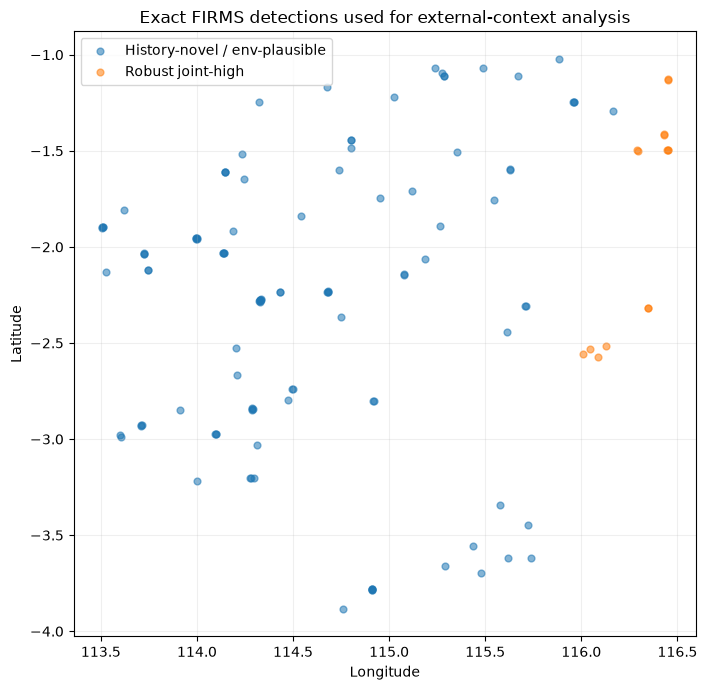

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\figures\01_exact_firms_context_points.png


In [25]:
# 24. Spatial plot of exact FIRMS detections

fig, ax = plt.subplots(figsize=(8, 7))

for group, subset in points_context.groupby("context_group"):
    ax.scatter(
        subset["firms_lon"],
        subset["firms_lat"],
        s=24,
        alpha=0.55,
        label=group,
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Exact FIRMS detections used for external-context analysis")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = FIGURES_DIR / "01_exact_firms_context_points.png"
plt.savefig(
    path,
    dpi=190,
    bbox_inches="tight",
)
plt.show()

print("Saved:", path)

In [26]:
# 25. Optional road-distance comparison plot

if cell_context["road_distance_km_min"].notna().any():
    groups = []

    labels = []

    for group in [
        "Robust joint-high",
        "History-novel / env-plausible",
    ]:
        values = (
            cell_context.loc[
                cell_context["context_group"].eq(group),
                "road_distance_km_min",
            ]
            .dropna()
            .to_numpy()
        )

        if len(values):
            groups.append(values)
            labels.append(group)

    if groups:
        fig, ax = plt.subplots(figsize=(8, 5))

        ax.boxplot(
            groups,
            tick_labels=labels,
        )

        ax.set_ylabel("Minimum mapped-access distance (km)")
        ax.set_title("Historical OSM accessibility context")
        ax.grid(alpha=0.2)

        plt.xticks(rotation=10)
        plt.tight_layout()

        path = FIGURES_DIR / "02_accessibility_comparison.png"
        plt.savefig(
            path,
            dpi=190,
            bbox_inches="tight",
        )
        plt.show()

        print("Saved:", path)
else:
    print("Road-distance plot skipped.")

Road-distance plot skipped.


In [27]:
# 26. Optional Dynamic World change-signal plot

if cell_context["dw_delta_trees_mean"].notna().any():
    plot_df = (
        cell_context[
            [
                "candidate_event_id",
                "context_group",
                "dw_delta_trees_mean",
                "dw_delta_crops_mean",
                "dw_delta_bare_mean",
            ]
        ]
        .copy()
    )

    x = np.arange(
        len(plot_df)
    )

    width = 0.25

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.bar(
        x - width,
        plot_df["dw_delta_trees_mean"],
        width,
        label="Trees Δ",
    )

    ax.bar(
        x,
        plot_df["dw_delta_crops_mean"],
        width,
        label="Crops Δ",
    )

    ax.bar(
        x + width,
        plot_df["dw_delta_bare_mean"],
        width,
        label="Bare Δ",
    )

    ax.axhline(
        0,
        linewidth=1,
    )

    ax.set_xticks(
        x,
        plot_df["candidate_event_id"],
        rotation=90,
    )

    ax.set_ylabel(
        "Dynamic World probability change\n"
        "(recent pre-event minus same-season prior year)"
    )

    ax.set_title(
        "Land-cover change signals — not confirmed deforestation"
    )

    ax.grid(
        axis="y",
        alpha=0.2,
    )

    ax.legend()

    plt.tight_layout()

    path = FIGURES_DIR / "03_dynamic_world_change_signals.png"
    plt.savefig(
        path,
        dpi=190,
        bbox_inches="tight",
    )
    plt.show()

    print("Saved:", path)

else:
    print("Dynamic World plot skipped.")

Dynamic World plot skipped.


# PART I — Interpretation framework

Do NOT create a single "anthropogenic probability" from these variables yet.

For each robust candidate, use an evidence profile:

### Natural-ignition evidence
- lightning detected near the hotspot shortly before FIRMS detection.

### Environmental susceptibility
- already estimated in NB23C.

### Land-cover / land-change context
- crops, built, bare, trees probabilities;
- year-over-year change signals.

### Accessibility context
- distance to mapped roads / tracks / paths.

### Peat context
- whether the detection lies on mapped peatland.

A candidate can be scientifically described as:

> "A hotspot with high fire-history and environmental anomaly, no detected lightning
> in the available network, close to mapped access infrastructure, and with pre-event
> land-cover change indicators."

It must NOT be described as:

> "This hotspot was intentionally set by humans."

That stronger statement requires independent ignition-cause evidence.

In [28]:
# 27. Save outputs

POINT_PATH = (
    EXPORT_DIR
    / "exact_firms_point_context.csv"
)

CELL_PATH = (
    EXPORT_DIR
    / "candidate_cell_day_context.csv"
)

SUMMARY_PATH = (
    EXPORT_DIR
    / "candidate_vs_control_context_summary.csv"
)

AVAILABILITY_PATH = (
    EXPORT_DIR
    / "external_source_availability.csv"
)

METADATA_PATH = (
    EXPORT_DIR
    / "nb23d_methodology_metadata.json"
)

points_context.to_csv(
    POINT_PATH,
    index=False,
)

cell_context.to_csv(
    CELL_PATH,
    index=False,
)

group_summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

availability.to_csv(
    AVAILABILITY_PATH,
    index=False,
)

metadata = {
    "notebook": "23D_external_context_data_integration",
    "analysis_land_fraction_threshold": LAND_THRESHOLD,
    "anomaly_threshold": ANOMALY_THRESHOLD,
    "dynamic_world_dataset": "GOOGLE/DYNAMICWORLD/V1",
    "dynamic_world_point_buffer_m": POINT_BUFFER_M,
    "dynamic_world_recent_window_days": 60,
    "dynamic_world_reference": (
        "same relative 60-day window one year earlier"
    ),
    "osm_source": "ohsome API historical OpenStreetMap snapshot",
    "osm_snapshot": OSM_SNAPSHOT_TIME,
    "osm_filter": "highway=* and geometry:line",
    "lightning": (
        "optional local event-level dataset; no source is fabricated "
        "when unavailable"
    ),
    "peatland": "optional properly sourced local polygon layer",
    "interpretation_limit": (
        "No output from this notebook is an anthropogenic, intentional-burning, "
        "illegal-burning, cigarette-ignition, plantation-clearing, "
        "or natural-ignition ground-truth label."
    ),
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved:")
for p in [
    POINT_PATH,
    CELL_PATH,
    SUMMARY_PATH,
    AVAILABILITY_PATH,
    METADATA_PATH,
]:
    print(" -", p)

Saved:
 - c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\exports\exact_firms_point_context.csv
 - c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\exports\candidate_cell_day_context.csv
 - c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\exports\candidate_vs_control_context_summary.csv
 - c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\exports\external_source_availability.csv
 - c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\exports\nb23d_methodology_metadata.json


In [29]:
# 28. Automatic next-step summary

print("=== NB23D next-step audit ===")
print()

display(availability)

print()
print("Candidate cell-days:", len(candidates))
print("Comparator cell-days:", len(controls))
print("Exact FIRMS points:", len(points_context))

source_flags = dict(
    zip(
        availability["Source"],
        availability["Available"],
    )
)

print()
print("Interpretation:")

if source_flags.get("Dynamic World", False):
    print("✓ land-cover / change context available")
else:
    print("○ Dynamic World not yet available")

if source_flags.get("Historical OSM accessibility", False):
    print("✓ historical mapped-access context available")
else:
    print("○ historical OSM access not yet available")

if source_flags.get("Lightning", False):
    print("✓ event-level lightning evidence available")
else:
    print("○ lightning unavailable — natural ignition evidence remains incomplete")

if source_flags.get("Peatland", False):
    print("✓ peatland context available")
else:
    print("○ peatland context unavailable")

print()
print(
    "Do not train an anthropogenic-vs-natural classifier from this table "
    "unless independently verified ignition-cause labels are acquired."
)

=== NB23D next-step audit ===



,Source,Available
0,Exact FIRMS,True
1,Dynamic World,False
2,Historical OSM accessibility,False
3,Lightning,False
4,Peatland,False



Candidate cell-days: 6
Comparator cell-days: 53
Exact FIRMS points: 126

Interpretation:
○ Dynamic World not yet available
○ historical OSM access not yet available
○ lightning unavailable — natural ignition evidence remains incomplete
○ peatland context unavailable

Do not train an anthropogenic-vs-natural classifier from this table unless independently verified ignition-cause labels are acquired.


# Decision after NB23D

### If only FIRMS is available
Do not proceed to ignition-context claims.

### If Dynamic World + historical OSM are available
You can perform a first **land-use/access contextual analysis**, but still cannot
infer ignition cause.

### If lightning is additionally available
You can contrast:
- candidates with positive natural-ignition evidence;
- candidates without detected lightning but with strong land-use/access context.

This supports **natural-plausibility vs anthropogenic-associated contextual analysis**,
not causal classification.

### GeoMAE decision
GeoMAE-inspired masked learning can still be developed afterward as the representation-learning
component, but its anomaly score should be interpreted alongside this external context rather
than treated as a human-ignition detector.